# Two-Channel Frazer–Hendry Formalism
___

This notebook reproduces the $T_{cc}(3875)^+$ line shape and pole trajectory in the **Frazer–Hendry (FH)** form, and then searches for **shadow poles**.

**Amplitude.** With a constant real symmetric matrix $M$ and the diagonal momentum matrix $k=\mathrm{diag}(k_1,k_2)$,
$$T(W)=\big[M-i\,k(W)\big]^{-1},\qquad D(W)=(M_{11}-ik_1)(M_{22}-ik_2)-M_{12}^2,$$
$$T_{11}=\frac{M_{22}-ik_2}{D},\qquad T_{12}=-\frac{M_{12}}{D},\qquad T_{22}=\frac{M_{11}-ik_1}{D}.$$
Because $\operatorname{Im}T^{-1}=-k$ above threshold, unitarity holds automatically; no Chew–Mandelstam real part appears. Channel 1 is $D^0(D^0\pi^+)$ and channel 2 is $D^0D^{*+}$.

**Observable.** The yield is $N\,k_1\,|T_{11}+\alpha_2T_{12}|^2$, averaged over each experimental mass bin (bin integration only: no resolution smearing, no bootstrap).

**Fit.** Differential evolution finds a global candidate and `scipy.optimize.least_squares` refines it; no hand-supplied start vector is used.

**Poles.** Poles are zeros of $D$ on one of four Riemann sheets $[tt],[bt],[bb],[tb]$ (first letter = channel 1, second = channel 2; $t$ keeps $k$, $b$ flips $k\to-k$). The pole is located with Delves–Lyness contour moments and followed as $M_{12}\to\lambda M_{12}$.

**Added in this notebook.** (i) An all-sheet pole search that looks for a *shadow pole*, a pole on a different sheet close to the primary one. (ii) Three amplitude extensions that can host a shadow: energy-dependent $M$, a bare-pole $K$-matrix, and a bare pole plus background. (iii) A survey of the fits with a causality screen.

___
## 1. Input and physical masses

All masses are in GeV. Channel 1 is the $D^0(D^0\pi^+)$ isobar with $M_1=m_{D^0}+m_{\pi^+}$ and $m_1=m_{D^0}$; channel 2 is $D^{*+}D^0$ with $M_2=m_{D^{*+}}$ and $m_2=m_{D^0}$. The thresholds are $W_{\mathrm{th},i}=M_i+m_i$, with $s_{\mathrm{th},i}=W_{\mathrm{th},i}^2$ and $s_{\mathrm{diff},i}=(M_i-m_i)^2$ (the pseudo-threshold that appears in the momentum).

`REAL_AXIS_EPS` implements $s\to s+i0^+$ on the real axis, `VIRTUAL_POLE_WINDOW_MEV` sets the branch of the fit (see §4) and `LAMBDA_STEP` is the step of the coupling scan.

In [230]:
from __future__ import annotations

from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import brentq, differential_evolution, least_squares, root


# =============================================================================
# 1. Input and physical masses (GeV)
# =============================================================================
DATA_PATH = Path(r"C:\Users\ermag\Desktop\NHP\ResLog\Sept2026\Fig1.csv")

m_D0 = 1.86484
m_Dstar_plus = 2.01026
m_pi_plus = 0.13957

# Channel 1: D0 + (D0 pi+) isobar; channel 2: D0 + D*+.
M1, m1 = m_D0 + m_pi_plus, m_D0
M2, m2 = m_Dstar_plus, m_D0

STH1 = (M1 + m1) ** 2
SDIFF1 = (M1 - m1) ** 2
STH2 = (M2 + m2) ** 2
SDIFF2 = (M2 - m2) ** 2
WTH1 = M1 + m1
WTH2 = M2 + m2

REAL_AXIS_EPS = 1.0e-14
VIRTUAL_POLE_WINDOW_MEV = 0.25
BIN_QUADRATURE_ORDER = 24
LAMBDA_STEP = 0.01

___
## 2. Reading the LHCb data and bin quadrature

`load_lhcb_data()` reads column 0 (mass), column 3 (yield), column 4 (uncertainty) and the bin edges in columns 1 and 2. Only points with finite values, $\sigma_i>0$ and $W_i^{\mathrm{high}}>W_i^{\mathrm{low}}$ are kept, so the data entering the fit are $\{W_i,Y_i,\sigma_i,W_i^{\mathrm{low}},W_i^{\mathrm{high}}\}$.

In [231]:
def load_lhcb_data(path: Path):
    df_data = pd.read_csv(path, comment="#")
    data_mass_MeV = df_data.iloc[:, 0].values * 1000.0
    data_yield = df_data.iloc[:, 3].values
    data_err = np.abs(df_data.iloc[:, 4].values)

    # Bin edges are present in CSV columns 1 and 2 (in GeV).
    bin_low_GeV = df_data.iloc[:, 1].values
    bin_high_GeV = df_data.iloc[:, 2].values
    data_mass_GeV = data_mass_MeV / 1000.0

    valid = (
        np.isfinite(data_mass_MeV)
        & np.isfinite(data_yield)
        & np.isfinite(data_err)
        & np.isfinite(bin_low_GeV)
        & np.isfinite(bin_high_GeV)
        & (data_err > 0.0)
        & (bin_high_GeV > bin_low_GeV)
    )
    return (
        df_data.loc[valid].reset_index(drop=True),
        data_mass_MeV[valid],
        data_mass_GeV[valid],
        bin_low_GeV[valid],
        bin_high_GeV[valid],
        data_yield[valid],
        data_err[valid],
    )

___
`make_bin_quadrature()` builds Gauss–Legendre nodes $x_j\in[-1,1]$ in every bin, so the model is compared with the **bin average**
$$\overline Y_i=\frac{1}{W_i^{\mathrm{high}}-W_i^{\mathrm{low}}}\int_{W_i^{\mathrm{low}}}^{W_i^{\mathrm{high}}}Y(W)\,dW\simeq\frac12\sum_j w_j\,Y(W_{ij}),\qquad W_{ij}=\frac{W^{\mathrm{high}}_i+W^{\mathrm{low}}_i}{2}+\frac{W^{\mathrm{high}}_i-W^{\mathrm{low}}_i}{2}x_j .$$
This matters near a threshold, where the line shape varies quickly inside one bin. It is bin integration, not detector-resolution convolution.

In [232]:
def make_bin_quadrature(bin_low_GeV, bin_high_GeV, order=BIN_QUADRATURE_ORDER):
    nodes, weights = np.polynomial.legendre.leggauss(order)
    midpoint = 0.5 * (bin_low_GeV + bin_high_GeV)
    half_width = 0.5 * (bin_high_GeV - bin_low_GeV)
    W_nodes = midpoint[:, None] + half_width[:, None] * nodes[None, :]
    return W_nodes, 0.5 * weights

___
## 3. Frazer–Hendry momenta and Riemann sheets

___
`momentum_top()` is the analytic channel momentum on the top (physical) sheet,
$$k_i(W)=\frac{i\sqrt{s_{\mathrm{th},i}-W^2}\,\sqrt{W^2-s_{\mathrm{diff},i}}}{2W}.$$
For exactly real $W$ the code uses $s\to s+i0^+$, which gives $k>0$ above threshold and $k=+i\kappa$ below it. Away from the real axis the complex $W$ itself fixes the continuation. Since $k(s^*)=-k(s)^*$, every sheet function obeys $D(W^*)=D(W)^*$: poles come in conjugate pairs on the *same* sheet.

In [233]:
def momentum_top(W, M, m):
    r"""Analytic momentum on the top/physical sheet.

    k(W) = i sqrt(s_th - W^2) sqrt(W^2 - s_diff) / (2 W).

    The infinitesimal +i0 for real W selects k>0 above threshold and k=+i*kappa
    below threshold. Away from the real axis, complex W itself specifies the
    continuation. Sheet 'b' is obtained by flipping the sign of k.
    """
    W_arr = np.asarray(W, dtype=complex)
    s = W_arr**2
    on_real = np.imag(W_arr) == 0.0
    if np.any(on_real):
        s = np.array(s, dtype=complex, copy=True)
        s[on_real] += 1j * REAL_AXIS_EPS
    sth = (M + m) ** 2
    sdiff = (M - m) ** 2
    return 1j * np.sqrt(sth - s) * np.sqrt(s - sdiff) / (2.0 * W_arr)

___
`momentum_on_sheet()` selects the sheet of one channel: $k_t=k$ and $k_b=-k$. A two-channel sheet is a pair of letters $[\sigma_1\sigma_2]$.

In [234]:
def momentum_on_sheet(W, M, m, letter):
    k = momentum_top(W, M, m)
    if letter == "t":
        return k
    if letter == "b":
        return -k
    raise ValueError("Sheet letters must be 't' or 'b'.")

___
`momenta_pair()` returns $(k_1,k_2)$ on the sheet $[\sigma_1\sigma_2]$, the four sheets being $[tt]$ (physical), $[bt]$, $[bb]$ and $[tb]$.

In [235]:
def momenta_pair(W, sheet="tt"):
    return (
        momentum_on_sheet(W, M1, m1, sheet[0]),
        momentum_on_sheet(W, M2, m2, sheet[1]),
    )

___
For real $W$ below threshold, $k=i\kappa$ with
$$\kappa(W)=\frac{\sqrt{(s_{\mathrm{th}}-W^2)(W^2-s_{\mathrm{diff}})}}{2W}>0 .$$

In [236]:
def kappa_below_threshold(W, M, m):
    """Positive |Im k| for real W below the two-body threshold."""
    W = np.asarray(W, dtype=float)
    sth = (M + m) ** 2
    sdiff = (M - m) ** 2
    radicand = np.maximum((sth - W**2) * (W**2 - sdiff), 0.0)
    return np.sqrt(radicand) / (2.0 * W)

___
The factor $k_1$ in the yield is the real, positive phase-space momentum of channel 1 on the data axis, $k_1=\max(\operatorname{Re}k_1^{\mathrm{top}},0)$.

In [237]:
def channel1_phase_space(W):
    """The p1 factor in the observed yield; k1 is real and positive on data."""
    return np.maximum(np.real(momentum_top(np.asarray(W, dtype=float), M1, m1)), 0.0)

___
## 4. FH T-matrix, line shape and fit

___
`fh_matrix_elements()` evaluates $T_{11},T_{12},T_{22}$ and $D$ on any sheet. The coupling scan uses $M_{12}\to\lambda M_{12}$: at $\lambda=0$ the channels decouple, at $\lambda=1$ the fitted amplitude is recovered.

In [238]:
def fh_matrix_elements(W, M11, M12, M22, lam=1.0, sheet="tt"):
    """Return T11, T12, T22, D for the Frazer-Hendry parametrization."""
    k1, k2 = momenta_pair(W, sheet=sheet)
    m12_eff = lam * M12
    d = (M11 - 1j * k1) * (M22 - 1j * k2) - m12_eff**2
    with np.errstate(divide="ignore", invalid="ignore", over="ignore"):
        t11 = (M22 - 1j * k2) / d
        t12 = -m12_eff / d
        t22 = (M11 - 1j * k1) / d
    return t11, t12, t22, d

___
The fitted observable is
$$Y(W)=N\,k_1(W)\,\big|T_{11}(W)+\alpha_2T_{12}(W)\big|^2,\qquad N=10^{\log_{10}N},$$
on the physical upper rim. $\alpha_2$ is the relative production strength of channel 2, and writing $N$ as a power of ten enforces $N>0$.

In [239]:
def line_shape(W, M11, M12, M22, alpha2, log10_norm):
    """Yield N*k1*|T11 + alpha2*T12|^2 on the physical upper rim."""
    W_arr = np.asarray(W, dtype=float)
    t11, t12, _, _ = fh_matrix_elements(W_arr, M11, M12, M22, lam=1.0, sheet="tt")
    f1 = t11 + alpha2 * t12
    norm = 10.0**log10_norm
    result = norm * channel1_phase_space(W_arr) * np.abs(f1) ** 2
    return np.real(result)

___
`bin_averaged_line_shape()` applies the quadrature weights: $\overline Y_i=\sum_j\tfrac12w_j\,Y(W_{ij})$.

In [240]:
def bin_averaged_line_shape(params, W_nodes, average_weights):
    return np.sum(line_shape(W_nodes, *params) * average_weights[None, :], axis=1)

___
`fit_residuals()` returns $r_i=(\overline Y_i-Y_i)/\sigma_i$, so $\chi^2=\sum_ir_i^2$. Non-finite predictions are replaced by a very large residual so the optimiser rejects them.

In [241]:
def fit_residuals(params, W_nodes, average_weights, y_data, y_err):
    prediction = bin_averaged_line_shape(params, W_nodes, average_weights)
    if not np.all(np.isfinite(prediction)):
        return np.full_like(y_data, 1.0e100, dtype=float)
    residual = (prediction - y_data) / y_err
    if not np.all(np.isfinite(residual)):
        return np.full_like(y_data, 1.0e100, dtype=float)
    return residual

___
A constant $M$-matrix can have several fit branches. To select the branch whose trajectory ends at a near-threshold virtual state, $M_{22}$ is bounded using the uncoupled channel-2 condition. At $\lambda=0$ the pole obeys $M_{22}-ik_2^{(b)}=0$; between the thresholds $k_2^{(b)}=-i\kappa_2$, hence $M_{22}=\kappa_2(W)$. Evaluating $\kappa_2$ at $W_{\mathrm{th},1}\pm\Delta$ gives the allowed interval. This is **derived from the chosen threshold window**, not taken from a published fit; change `VIRTUAL_POLE_WINDOW_MEV` to explore other branches.

In [242]:
def derive_M22_bounds_for_virtual_branch(window_MeV=VIRTUAL_POLE_WINDOW_MEV):
    """Derive M22 range from M22 - i*k2_b=0 at lambda=0 near threshold 1.

    For W between thresholds, k2_top=+i*kappa and k2_bottom=-i*kappa. Hence
    M22 - i*k2_bottom = M22 - kappa = 0, or M22=kappa. The resulting search
    interval is determined from the selected threshold window, not a paper fit.
    """
    delta = window_MeV / 1000.0
    Wlo = WTH1 - delta
    Whi = WTH1 + delta
    values = kappa_below_threshold(np.array([Wlo, Whi]), M2, m2)
    low, high = float(np.min(values)), float(np.max(values))
    margin = min(1.0e-7, 0.02 * (high - low))
    return low + margin, high - margin

___
`fit_without_manual_initial_guess()` runs differential evolution over the bounds
$$M_{11}\in[-5,5],\ M_{12}\in[10^{-4},2],\ M_{22}\in[\kappa_{\min},\kappa_{\max}],\ \alpha_2\in[-5,5],\ \log_{10}N\in[-5,9],$$
then refines the result with a trust-region least-squares fit. Restricting $M_{12}\ge10^{-4}$ removes a sign degeneracy, because only $M_{12}^2$ enters $D$ and the sign of $T_{12}$ is absorbed by $\alpha_2$.

In [243]:
def fit_without_manual_initial_guess(W_nodes, average_weights, y_data, y_err):
    m22_low, m22_high = derive_M22_bounds_for_virtual_branch()
    # M12 >= 0 removes a channel-phase/sign degeneracy. N is parameterized as
    # 10**log10_norm to enforce a positive normalization.
    bounds = [
        (-5.0, 5.0),            # M11 [GeV]
        (1.0e-4, 2.0),          # M12 [GeV]
        (m22_low, m22_high),    # M22 [GeV], derived virtual-state branch interval
        (-5.0, 5.0),            # alpha2
        (-5.0, 9.0),            # log10(N)
    ]

    def objective(params):
        r = fit_residuals(params, W_nodes, average_weights, y_data, y_err)
        return float(r @ r) if np.all(np.isfinite(r)) else 1.0e100

    print("Running differential evolution for the FH model (no user-supplied start vector)...")
    de = differential_evolution(
        objective,
        bounds=bounds,
        strategy="best1bin",
        maxiter=900,
        popsize=16,
        tol=2.0e-5,
        mutation=(0.5, 1.0),
        recombination=0.7,
        init="latinhypercube",
        polish=False,
        seed=20261010,
        updating="immediate",
        workers=1,
        disp=False,
    )

    lower = np.array([b[0] for b in bounds], dtype=float)
    upper = np.array([b[1] for b in bounds], dtype=float)
    ls = least_squares(
        fit_residuals,
        x0=de.x,
        args=(W_nodes, average_weights, y_data, y_err),
        bounds=(lower, upper),
        method="trf",
        x_scale="jac",
        ftol=1.0e-12,
        xtol=1.0e-12,
        gtol=1.0e-12,
        max_nfev=12000,
        verbose=0,
    )
    params = ls.x
    final_residuals = fit_residuals(params, W_nodes, average_weights, y_data, y_err)
    chi2 = float(final_residuals @ final_residuals)
    dof = len(y_data) - len(params)
    return params, chi2, dof, bounds, de, ls

___
## 5. Delves–Lyness contour method and pole trajectory

___
`determinant_denominator()` is the zero-function of the pole search, $D_\sigma(W)=(M_{11}-ik_1)(M_{22}-ik_2)-\lambda^2M_{12}^2$ on sheet $\sigma$. A pole of the amplitude is a zero of $D_\sigma$.

In [244]:
def determinant_denominator(W, M11, M12, M22, lam=1.0, sheet="tt"):
    _, _, _, d = fh_matrix_elements(W, M11, lam * M12, M22, lam=1.0, sheet=sheet)
    return d

___
Given the power sums $p_k=\sum_jW_j^k$ of $n$ unknown roots, the Newton identities $m\,e_m=\sum_{k=1}^m(-1)^{k-1}e_{m-k}\,p_k$ give the elementary symmetric polynomials $e_m$, hence the polynomial $\prod_j(W-W_j)$, whose roots are found with `np.roots`.

In [245]:
def _roots_from_power_sums(power_sums, n_roots):
    if n_roots == 1:
        return np.array([power_sums[1]], dtype=complex)
    elementary = np.zeros(n_roots + 1, dtype=complex)
    elementary[0] = 1.0
    for m in range(1, n_roots + 1):
        total = 0.0j
        for k in range(1, m + 1):
            total += ((-1) ** (k - 1)) * elementary[m - k] * power_sums[k]
        elementary[m] = total / m
    coefficients = np.array([((-1) ** k) * elementary[k] for k in range(n_roots + 1)], complex)
    return np.roots(coefficients)

___
`delves_lyness_roots()` locates all zeros of an analytic function inside a counter-clockwise polygon. The logarithmic moments
$$A_k=\frac1{2\pi i}\oint W^k\frac{D'(W)}{D(W)}\,dW=\sum_{j}W_j^{\,k}$$
are the power sums of the enclosed zeros; $A_0$ is their number. The contour must avoid the real-axis branch cuts, and the coordinates are rescaled for numerical stability. If $A_0$ is not close to an integer the contour is too close to a zero and the result is rejected.

In [246]:
def delves_lyness_roots(func, vertices, n_per_side=800, derivative_step=5.0e-7,
                         integer_tolerance=0.25, max_moments=8):
    """Find zeros inside a CCW polygon using Delves-Lyness logarithmic moments.

    A_k = (1/(2*pi*i)) contour_integral W**k D'(W)/D(W) dW is the sum of
    k-th powers of enclosed zeros. Here D is analytic and has no poles inside
    the contour, which is placed away from the real-axis branch cuts.
    """
    vertices = [complex(v) for v in vertices]
    contour_points, contour_steps = [], []
    for a, b in zip(vertices, vertices[1:] + vertices[:1]):
        t = np.arange(n_per_side, dtype=float) / n_per_side
        contour_points.append(a + (b - a) * t)
        contour_steps.append(np.full(n_per_side, (b - a) / n_per_side, complex))
    z = np.concatenate(contour_points)
    dz = np.concatenate(contour_steps)

    fz = np.asarray(func(z), dtype=complex)
    fprime = (np.asarray(func(z + derivative_step), dtype=complex)
              - np.asarray(func(z - derivative_step), dtype=complex)) / (2.0 * derivative_step)
    if not np.all(np.isfinite(fz)) or np.min(np.abs(fz)) < 1.0e-14:
        return np.array([], dtype=complex), complex(np.nan, np.nan)

    xmin, xmax = min(v.real for v in vertices), max(v.real for v in vertices)
    ymin, ymax = min(v.imag for v in vertices), max(v.imag for v in vertices)
    center = 0.5 * (xmin + xmax) + 0.5j * (ymin + ymax)
    scale = max(0.5 * (xmax - xmin), 0.5 * (ymax - ymin))
    u = (z - center) / scale
    log_derivative_dz = (fprime / fz) * dz
    powers = np.empty(max_moments + 1, dtype=complex)
    for k in range(max_moments + 1):
        powers[k] = np.sum((u**k) * log_derivative_dz) / (2j * np.pi)
    n_est = powers[0]
    n_roots = int(np.rint(n_est.real))
    if (n_roots < 1 or n_roots > max_moments
        or abs(n_est.imag) > integer_tolerance
        or abs(n_est.real - n_roots) > integer_tolerance):
        return np.array([], dtype=complex), n_est

    roots_u = _roots_from_power_sums(powers, n_roots)
    roots = center + scale * roots_u
    inside = ((roots.real > xmin - 1.0e-9) & (roots.real < xmax + 1.0e-9)
              & (roots.imag > ymin - 1.0e-9) & (roots.imag < ymax + 1.0e-9))
    return roots[inside], n_est

___
`rectangular_contour()` returns the four vertices of a counter-clockwise rectangle.

In [247]:
def rectangular_contour(xmin, xmax, ymin, ymax):
    return [complex(xmin, ymin), complex(xmax, ymin),
            complex(xmax, ymax), complex(xmin, ymax)]

___
`refine_complex_root()` polishes a contour estimate by solving $\operatorname{Re}D=\operatorname{Im}D=0$ with MINPACK's `hybr`, and falls back to the unrefined value if the residual stays above $10^{-7}$.

In [248]:
def refine_complex_root(func, z0, tol=1.0e-11):
    def system(x):
        value = func(complex(x[0], x[1]))
        return [value.real, value.imag]
    sol = root(system, [z0.real, z0.imag], method="hybr", tol=tol)
    z = complex(sol.x[0], sol.x[1])
    if not (np.isfinite(z.real) and np.isfinite(z.imag)) or abs(func(z)) > 1.0e-7:
        return z0
    return z

___
`find_lambda1_pole_delves_lyness()` searches the lower half-plane of $[bt]$ in $\operatorname{Re}W\in[3.860,3.885]$ GeV, $\operatorname{Im}W\in[-12,-0.1]$ MeV, and selects the accepted zero nearest the $D^{*+}D^0$ threshold. Note that this contour excludes $|\operatorname{Im}W|<0.1$ MeV; the shadow search below reaches 1 keV.

In [249]:
def find_lambda1_pole_delves_lyness(params):
    M11, M12, M22, _, _ = params
    def d_bt(W):
        return determinant_denominator(W, M11, M12, M22, lam=1.0, sheet="bt")
    contour = rectangular_contour(3.860, 3.885, -0.012, -1.0e-4)
    roots_found, count = delves_lyness_roots(d_bt, contour, n_per_side=1000)
    candidates = []
    for z0 in roots_found:
        z = refine_complex_root(d_bt, z0)
        if z.imag < 0.0 and abs(d_bt(z)) < 1.0e-5:
            candidates.append(z)
    if not candidates:
        raise RuntimeError(
            "Delves-Lyness did not find an accepted [bt] pole inside its contour. "
            "Inspect the fitted branch or enlarge/refine the contour."
        )
    selected = min(candidates, key=lambda z: abs(z - WTH2))
    return selected, np.asarray(candidates, dtype=complex), count

___
`solve_complex_zero()` finds a zero of an analytic function from a complex starting point and returns the residual $|D|$.

In [250]:
def solve_complex_zero(func, z_start, tol=1.0e-10):
    def system(x):
        value = func(complex(x[0], x[1]))
        return [value.real, value.imag]
    sol = root(system, [z_start.real, z_start.imag], method="hybr", tol=tol)
    z = complex(sol.x[0], sol.x[1])
    if not (np.isfinite(z.real) and np.isfinite(z.imag)):
        return z, np.inf
    return z, abs(func(z))

___
At $\lambda=0$ the pole is real: the condition $\operatorname{Re}(M_{22}-ik_2^{(b)})=0$ is bracketed on a fine grid below $W_{\mathrm{th},2}$ and solved with Brent's method. The root nearest $W_{\mathrm{th},1}$ is the virtual state on $[tb]$.

In [251]:
def find_lambda0_virtual_pole(params):
    M22 = params[2]
    def condition(W):
        k2_bottom = momentum_on_sheet(complex(W, REAL_AXIS_EPS), M2, m2, "b")
        return float(np.real(M22 - 1j * k2_bottom))
    grid = np.linspace(WTH1 - 0.010, WTH2 - 1.0e-7, 2000)
    vals = np.array([condition(w) for w in grid])
    brackets = []
    for a, b, fa, fb in zip(grid[:-1], grid[1:], vals[:-1], vals[1:]):
        if fa == 0.0:
            brackets.append((a, a))
        elif fa * fb < 0.0:
            brackets.append((a, b))
    if not brackets:
        raise RuntimeError("No real lambda=0 virtual pole found on [tb] in the near-threshold interval.")
    roots_found = [a if a == b else brentq(condition, a, b, xtol=1.0e-13) for a, b in brackets]
    return complex(min(roots_found, key=lambda w: abs(w - WTH1)), 0.0)

___
`pole_trajectory()` follows the pole from $\lambda=1$ down to $\lambda=0$. At each step the previous pole is the starting point; if the continuation fails or crosses to the wrong half-plane, the other sheet ($[bt]\leftrightarrow[tb]$) is tried. The accepted sign conventions are $\operatorname{Im}W<0$ on $[bt]$ and $\operatorname{Im}W>0$ on $[tb]$.

In [252]:
def pole_trajectory(params, lambda_values=None):
    if lambda_values is None:
        lambda_values = np.round(np.arange(0.0, 1.0 + 0.5 * LAMBDA_STEP, LAMBDA_STEP), 2)
    lambda_values = np.asarray(lambda_values, dtype=float)
    pole1, _, _ = find_lambda1_pole_delves_lyness(params)
    found = {1.0: pole1}
    sheets = {1.0: "bt"}
    previous = pole1
    current_sheet = "bt"
    M11, M12, M22 = params[:3]

    for lam in np.sort(lambda_values)[::-1]:
        lam = float(np.round(lam, 8))
        if lam >= 1.0 - 1.0e-10:
            continue
        if lam <= 1.0e-10:
            pole0 = find_lambda0_virtual_pole(params)
            found[lam] = pole0
            sheets[lam] = "tb"
            previous = pole0
            current_sheet = "tb"
            continue

        def d_current(W):
            return determinant_denominator(W, M11, M12, M22, lam=lam, sheet=current_sheet)
        z, residual = solve_complex_zero(d_current, previous)
        sign_ok = (current_sheet == "bt" and z.imag < 0.0) or (current_sheet == "tb" and z.imag > 0.0)
        accepted = residual < 1.0e-6 and sign_ok and 3.84 < z.real < 3.90

        if not accepted:
            other = "tb" if current_sheet == "bt" else "bt"
            other_imag_sign = 1.0 if other == "tb" else -1.0
            seed = complex(previous.real, other_imag_sign * max(abs(previous.imag), 1.0e-5))
            def d_other(W):
                return determinant_denominator(W, M11, M12, M22, lam=lam, sheet=other)
            z2, r2 = solve_complex_zero(d_other, seed)
            sign_ok2 = (other == "bt" and z2.imag < 0.0) or (other == "tb" and z2.imag > 0.0)
            if r2 < 1.0e-6 and sign_ok2 and 3.84 < z2.real < 3.90:
                z, residual, current_sheet, accepted = z2, r2, other, True
        if not accepted:
            raise RuntimeError(
                f"Pole continuation failed at lambda={lam:.2f}; residual={residual:.3e}. "
                "Try a smaller LAMBDA_STEP or inspect the fitted branch."
            )
        found[lam] = z
        sheets[lam] = current_sheet
        previous = z

    pole_values = np.array([found[float(np.round(x, 8))] for x in lambda_values], dtype=complex)
    sheet_values = [sheets[float(np.round(x, 8))] for x in lambda_values]
    return lambda_values, pole_values, sheet_values

___
## 6. Plotting the reproduced figures

___
`make_fig1()` shows the fitted line shape on the data (top) and a zoom around the $D^{*+}D^0$ threshold on the 200-keV display scale (bottom).

In [253]:
def make_fig1(W_centers, y_data, y_err, params, chi2, dof, output_path=r"C:\Users\ermag\Desktop\NHP\ResLog\Oct2026\Test2\Fig1_FH_reproduced.png"):
    W_plot = np.linspace(3.870, 3.900, 2500)
    y_plot = line_shape(W_plot, *params)
    fig, (ax_full, ax_zoom) = plt.subplots(1, 2, figsize=(13, 5))
    ax_full.errorbar(W_centers * 1000, y_data, yerr=y_err, fmt="o", ms=3.5,
                     color="black", ecolor="black", elinewidth=0.8, capsize=1.5,
                     label="LHCb data")
    ax_full.plot(W_plot * 1000, y_plot, color="blue", lw=1.6,
                 label="FH least-squares fit")
    ax_full.set_xlim(3869, 3900)
    ax_full.set_ylabel("Yield (500-keV scale)")
    ax_full.set_title(rf"Frazer-Hendry fit: $\chi^2/\mathrm{{dof}}={chi2:.2f}/{dof}={chi2/dof:.3f}$")
    ax_full.legend(frameon=False, loc="upper right")
    ax_full.tick_params(direction="in", which="both", top=True, right=True)
    ax_full.axvline(WTH2 * 1000, color="red", ls=":", lw=1.4,
                        label=r"$D^{*+}D^0$ threshold")
    ax_full.axvline(WTH1 * 1000, color="gray", ls=":", lw=1.4,
                            label=r"$D^0D^0\pi^+$ threshold")

    scale = 200.0 / 500.0
    mask = (W_centers >= 3.8730) & (W_centers <= 3.8770)
    plot_mask = (W_plot >= 3.8730) & (W_plot <= 3.8770)
    ax_zoom.errorbar(W_centers[mask] * 1000, y_data[mask] * scale, yerr=y_err[mask] * scale,
                     fmt="o", ms=4, color="black", ecolor="black", elinewidth=0.8,
                     capsize=1.5, label="LHCb data (200-keV display scale)")
    ax_zoom.plot(W_plot[plot_mask] * 1000, y_plot[plot_mask] * scale, color="blue", lw=1.6,
                 label="Same fitted line shape")
    ax_zoom.axvline(WTH2 * 1000, color="red", ls=":", lw=1.4,
                    label=r"$D^{*+}D^0$ threshold")
    ax_zoom.set_xlim(3874, 3876)
    ax_zoom.set_xlabel(r"$M_{D^0D^0\pi^+}$ (MeV)")
    ax_zoom.set_ylabel("Yield (200-keV display scale)")
    ax_zoom.legend(frameon=False, loc="upper right", fontsize=8)
    ax_zoom.tick_params(direction="in", which="both", top=True, right=True)
    fig.tight_layout()
    fig.savefig(output_path, dpi=220, bbox_inches="tight")
    return fig

___
`make_fig2()` plots the pole trajectory $M_{12}\to\lambda M_{12}$ in the complex $W$ plane, with $[bt]$ points filled black and $[tb]$ points open magenta.

In [254]:
def make_fig2(lambda_values, poles, sheets, output_path=r"C:\Users\ermag\Desktop\NHP\ResLog\Oct2026\Test2\Fig2_FH_reproduced.png"):
    fig, ax = plt.subplots(figsize=(9, 6))
    sheets_array = np.asarray(sheets, dtype=object)
    for sheet, label, color, face in (
        ("bt", "RS-II [bt]", "black", "black"),
        ("tb", "RS-IV [tb]", "blue", "none"),
    ):
        mask = sheets_array == sheet
        if np.any(mask):
            ax.plot(poles.real[mask] * 1000, poles.imag[mask] * 1000,
                    linestyle="none", marker="o", ms=4.2, markeredgecolor=color,
                    markerfacecolor=face, label=label)
    ax.axhline(0, color="black", lw=0.8)
    ax.axvline(WTH1 * 1000, color="red", ls=":", lw=1.2)
    ax.axvline(WTH2 * 1000, color="red", ls=":", lw=1.2)
    ax.text(WTH1 * 1000 + 0.03, 0.30, r"$D^0D^0\pi^+$", fontsize=9)
    ax.text(WTH2 * 1000 - 0.15, 0.30, r"$D^0D^{*+}$", fontsize=9, ha="right")
    i0 = int(np.argmin(np.abs(lambda_values)))
    i1 = int(np.argmin(np.abs(lambda_values - 1.0)))
    ax.annotate(r"$\lambda=0$", (poles.real[i0] * 1000, poles.imag[i0] * 1000),
                xytext=(5, 7), textcoords="offset points", fontsize=9)
    ax.annotate(r"$\lambda=1$", (poles.real[i1] * 1000, poles.imag[i1] * 1000),
                xytext=(-35, -14), textcoords="offset points", fontsize=9)
    ax.set_xlabel(r"Pole mass $\mathrm{Re}\,W_{\rm pole}$ (MeV)")
    ax.set_ylabel(r"$\mathrm{Im}\,W_{\rm pole}$ (MeV)")
    ax.set_title(r"Frazer-Hendry pole trajectory: $M_{12}\rightarrow\lambda M_{12}$")
    ax.set_xlim(3869.0, 3875.5)
    ax.set_ylim(-0.4, 0.3)
    ax.legend(frameon=False, loc="lower left")
    ax.grid(True, alpha=0.5)
    ax.tick_params(direction="in", which="both", top=True, right=True)
    fig.tight_layout()
    fig.savefig(output_path, dpi=220, bbox_inches="tight")
    return fig

___
## 7. Shadow-pole search

A *shadow pole* is a pole on a sheet **different** from that of the primary pole and lying close to it, so that the two form a pole–shadow pair. In the notation of the DNN classes this separates the topologies $[1_{bt},0_{bb},0_{tb}]$ (isolated pole) and $[1_{bt},1_{bb},0_{tb}]$ (pole + shadow).

Every pole is a zero of $D_\sigma(W)$ on one of four sheets. For a real $M$ we have $D_\sigma(W^*)=D_\sigma(W)^*$ (see §3), so zeros come in conjugate pairs $(W,W^*)$ on the same sheet and only one representative is reported. The half-plane convention is the one already used by `pole_trajectory()`: $\operatorname{Im}W<0$ for $[tt],[bt],[bb]$ and $\operatorname{Im}W>0$ for $[tb]$.

**Why the constant-$M$ fit cannot contain a shadow.** Requiring $D_\sigma(W_0)=0$ means $(M_{11}-ik_1)(M_{22}-ik_2)=M_{12}^2$, which must be real and positive. Writing $a=M_{11}-ik_1$, $b=M_{22}-ik_2$: $\operatorname{Im}(ab)=0$ is linear in $M_{22}$ for any $M_{11}$, and the remaining condition is $M_{12}^2=\operatorname{Re}(ab)>0$. Scanning $M_{11}$ for 3000 random pole positions per sheet, this is never satisfiable on $[tt]$ or $[bb]$, and always satisfiable on $[bt]$ and $[tb]$. So with energy-independent real $M$ a complex $[bb]$ pole is impossible and the topology can only be an isolated $[bt]$ pole; the absence of complex $[tt]$ poles is the expected causality statement.

**Pole counting.** The window is the pole-sampling window of the DNN training set, $\varepsilon_2-5\le\operatorname{Re}E\le\varepsilon_2+10$ MeV and $|\operatorname{Im}E|\le20$ MeV, so the label $[n_{bt},n_{bb},n_{tb}]$ is directly comparable with the DNN classes. The channel momenta reported for each pole use the same sheet functions as the fit.

In [255]:
# =============================================================================
# Shadow-pole search
# =============================================================================
SHEETS = ("tt", "bt", "bb", "tb")

# Half-plane in which the representative of each (W, W*) pair is reported. This
# is the same convention already used by pole_trajectory(): sheets with channel 1
# on the cut-flipped branch ([bt], [bb]) carry Im W < 0, while [tb] carries
# Im W > 0. The conjugate partner W* is a zero of the same sheet function
# (real K-matrix), so it is not a separate state.
SHADOW_HALF_PLANE = {"tt": -1, "bt": -1, "bb": -1, "tb": +1}

# Pole-counting window, identical to the pole-sampling window used to build the
# DNN training set: eps2-5 <= Re E <= eps2+10 MeV and |Im E| <= 20 MeV.
COUNT_RE_WINDOW_MEV = (-5.0, 10.0)   # relative to the D*+ D0 threshold
COUNT_IM_MAX_MEV = 20.0

# A pole on another sheet closer than this (in W) to the primary pole is
# reported as its shadow candidate.
SHADOW_MAX_SEPARATION_MEV = 15.0


def channel_momentum_on_sheet(W, M, m, letter):
    """Physical channel momentum k (GeV) on the given sheet letter, from the same k used in the fit."""
    return complex(momentum_on_sheet(complex(W), M, m, letter))


class TaggedParams(np.ndarray):
    """ndarray carrying a .model tag so the pole search can dispatch on the amplitude model."""
    model = None


def tag_model(theta, model):
    out = np.asarray(theta, dtype=float).view(TaggedParams)
    out.model = model
    return out


def _det_on_sheet(params, sheet, lam=1.0):
    """Zero-function of the pole search. Untagged 5-vectors are the constant-M FH model."""
    model = getattr(params, "model", None)
    if model is not None:
        return lambda W: MODEL_DETERMINANT[model](W, params, sheet)
    M11, M12, M22 = params[:3]

    def det(W):
        return determinant_denominator(W, M11, M12, M22, lam=lam, sheet=sheet)

    return det


def _in_search_window(z, re_range_GeV, im_max_GeV):
    return (
        np.isfinite(z.real)
        and np.isfinite(z.imag)
        and re_range_GeV[0] <= z.real <= re_range_GeV[1]
        and abs(z.imag) <= im_max_GeV
    )


def _real_axis_roots(det, w_lo, w_hi, n_grid=4000, residual_tol=1.0e-8):
    """Real zeros below the lower threshold, where D is real on every sheet."""
    grid = np.linspace(w_lo, w_hi, n_grid)
    values = np.array([complex(det(W)).real for W in grid])
    roots = []
    for a, b, fa, fb in zip(grid[:-1], grid[1:], values[:-1], values[1:]):
        if fa * fb < 0.0:
            z = brentq(lambda W: complex(det(W)).real, a, b, xtol=1.0e-14)
            if abs(det(z)) < residual_tol:   # rejects sign flips at poles of D
                roots.append(complex(z, 0.0))
    return roots

___
`search_poles_all_sheets()` combines three methods. (i) Delves–Lyness counting on every sheet over $|\operatorname{Im}W|\in[1~\mathrm{keV},20~\mathrm{MeV}]$; unlike §5 the contour reaches 1 keV from the real axis, so narrow poles are not excluded. (ii) A multi-start complex root finder on a log-spaced seed grid, which recovers zeros lying too close to a contour edge for the contour integral to resolve. (iii) A real-axis scan below $W_{\mathrm{th},1}$ for bound and virtual states. A zero is accepted only if $|D(W)|<10^{-7}$ after refinement.

In [256]:
def search_poles_all_sheets(
    params,
    re_range_GeV=(3.860, 3.890),
    im_max_GeV=0.020,
    im_min_GeV=1.0e-6,
    n_per_side=1600,
    residual_tol=1.0e-7,
    use_delves_lyness=True,
    use_seed_search=True,
    scan_real_axis=True,
):
    """
    Search every zero of det(1-KC) on [tt], [bt], [bb] and [tb].

    The window spans |Im W| from im_min_GeV (1 keV) to im_max_GeV (20 MeV), so poles
    hugging the real axis are not excluded. Three complementary methods are used:
      1. Delves-Lyness contour counting (exhaustive, but loses accuracy for zeros
         lying very close to the contour);
      2. multi-start complex Newton/hybrid root finding on a log-spaced seed grid
         (catches what the contour method misses);
      3. a real-axis scan below the D0 D0 pi+ threshold (bound / virtual states).
    A zero is accepted only when |D(W)| < residual_tol after refinement.
    """
    found = []

    def register(z, sheet, source):
        z = complex(z)
        residual = float(abs(_det_on_sheet(params, sheet)(z)))
        if residual >= residual_tol or not _in_search_window(z, re_range_GeV, im_max_GeV):
            return
        for other in found:
            if other["sheet"] == sheet and abs(other["W"] - z) < 1.0e-7:
                return
        p1 = channel_momentum_on_sheet(z, M1, m1, sheet[0])
        p2 = channel_momentum_on_sheet(z, M2, m2, sheet[1])
        found.append(
            {
                "sheet": sheet,
                "W": z,
                "source": source,
                "residual": residual,
                "p1": p1,
                "p2": p2,
            }
        )

    re_seeds = np.linspace(re_range_GeV[0] + 0.006, re_range_GeV[1] - 0.006, 13)
    im_seeds = np.logspace(np.log10(5.0e-6), np.log10(0.012), 8)

    for sheet in SHEETS:
        det = _det_on_sheet(params, sheet)
        sign = SHADOW_HALF_PLANE[sheet]

        if use_delves_lyness:
            y_a, y_b = sorted((sign * im_min_GeV, sign * im_max_GeV))
            contour = rectangular_contour(re_range_GeV[0], re_range_GeV[1], y_a, y_b)
            roots, _ = delves_lyness_roots(
                det, contour, n_per_side=n_per_side, derivative_step=5.0e-7
            )
            for z0 in roots:
                z = refine_complex_root(det, z0)
                if z.imag * sign > 0.0:
                    register(z, sheet, "DL")

        if use_seed_search:
            for x0 in re_seeds:
                for y0 in im_seeds:
                    z, res = solve_complex_zero(det, complex(x0, sign * y0))
                    if np.isfinite(res) and res < residual_tol and z.imag * sign > 1.0e-9:
                        register(z, sheet, "seed")

        if scan_real_axis:
            for z in _real_axis_roots(det, WTH1 - 0.020, WTH1 - 1.0e-9):
                register(z, sheet, "real-axis")

    found.sort(key=lambda c: abs(c["W"] - WTH2))
    return found

___
`find_shadow_poles()` selects the primary pole (the unphysical-sheet pole nearest the $D^{*+}D^0$ threshold, the same rule as `find_lambda1_pole_delves_lyness()`) and returns every pole on a *different* sheet within `SHADOW_MAX_SEPARATION_MEV` as a shadow candidate. `count_pole_topology()` returns $[n_{bt},n_{bb},n_{tb}]$. `acausal_poles()` flags complex poles on the physical sheet $[tt]$, which violate causality.

In [257]:
def _in_counting_window(z):
    re_rel = (z.real - WTH2) * 1000.0
    return (
        COUNT_RE_WINDOW_MEV[0] <= re_rel <= COUNT_RE_WINDOW_MEV[1]
        and abs(z.imag) * 1000.0 <= COUNT_IM_MAX_MEV
    )


def count_pole_topology(poles):
    """Pole counting [n_bt, n_bb, n_tb], using the same labels as the DNN classes."""
    counts = {s: 0 for s in ("bt", "bb", "tb")}
    for pole in poles:
        if pole["sheet"] in counts and _in_counting_window(pole["W"]):
            counts[pole["sheet"]] += 1
    label = f"[{counts['bt']}bt, {counts['bb']}bb, {counts['tb']}tb]"
    return counts, label


def find_shadow_poles(params, poles=None, primary=None,
                      max_separation_MeV=SHADOW_MAX_SEPARATION_MEV, **search_kwargs):
    """
    Locate the primary pole and any shadow candidates on the other sheets.

    primary : optional pole dict. By default it is the unphysical-sheet pole
              nearest the D*+ D0 threshold, which is the selection rule of
              find_physical_pole_by_delves_lyness().
    A shadow candidate is a pole on a *different* sheet within max_separation_MeV
    of the primary pole.
    """
    if poles is None:
        poles = search_poles_all_sheets(params, **search_kwargs)

    in_window = [p for p in poles if p["sheet"] != "tt" and _in_counting_window(p["W"])]
    if primary is None:
        if not in_window:
            return {"primary": None, "shadows": [], "poles": poles,
                    "counts": count_pole_topology(poles)[0],
                    "topology": count_pole_topology(poles)[1]}
        primary = min(in_window, key=lambda p: abs(p["W"] - WTH2))

    shadows = []
    for pole in poles:
        if pole["sheet"] == primary["sheet"]:
            continue
        separation = abs(pole["W"] - primary["W"]) * 1000.0
        if separation <= max_separation_MeV:
            shadows.append({**pole, "separation_MeV": separation,
                            "dRe_MeV": (pole["W"].real - primary["W"].real) * 1000.0,
                            "dIm_MeV": (pole["W"].imag - primary["W"].imag) * 1000.0})
    shadows.sort(key=lambda p: p["separation_MeV"])

    counts, label = count_pole_topology(poles)
    return {"primary": primary, "shadows": shadows, "poles": poles,
            "counts": counts, "topology": label}


def acausal_poles(poles, tol_GeV=1.0e-7):
    """Complex poles on the physical sheet [tt] violate causality (real-axis bound states are allowed)."""
    return [p for p in poles if p["sheet"] == "tt" and abs(p["W"].imag) > tol_GeV]

___
Reporting and plotting. `make_fig_shadow()` draws every pole found in the complex $W$ plane, with the primary pole starred and arrows to any shadow candidates.

In [258]:
def poles_to_dataframe(poles, primary=None):
    rows = []
    for p in poles:
        z = p["W"]
        rows.append(
            {
                "sheet": f"[{p['sheet']}]",
                "Re_W_MeV": z.real * 1000.0,
                "Im_W_MeV": z.imag * 1000.0,
                "Re_W_minus_th2_MeV": (z.real - WTH2) * 1000.0,
                "Re_W_minus_th1_MeV": (z.real - WTH1) * 1000.0,
                "Re_p1_MeV": p["p1"].real * 1000.0,
                "Im_p1_MeV": p["p1"].imag * 1000.0,
                "Re_p2_MeV": p["p2"].real * 1000.0,
                "Im_p2_MeV": p["p2"].imag * 1000.0,
                "|D|": p["residual"],
                "found_by": p["source"],
                "in_count_window": _in_counting_window(z),
                "is_primary": primary is not None and p is primary,
            }
        )
    return pd.DataFrame(rows)


def report_shadow_search(result):
    primary, shadows = result["primary"], result["shadows"]
    print("\n================ SHADOW-POLE SEARCH ================")
    print(f"Pole counting in window (eps2{COUNT_RE_WINDOW_MEV[0]:+.0f}..{COUNT_RE_WINDOW_MEV[1]:+.0f} MeV, "
          f"|Im|<={COUNT_IM_MAX_MEV:.0f} MeV): {result['topology']}")
    if primary is None:
        print("No pole found on an unphysical sheet inside the counting window.")
        return
    bad = acausal_poles(result["poles"])
    if bad:
        print(f"WARNING: {len(bad)} complex pole(s) on the physical sheet [tt] -> acausal solution:")
        for p in bad:
            print(f"   W = {p['W'].real*1000:.4f} {p['W'].imag*1000:+.4f}i MeV")
    z = primary["W"]
    print(f"Primary pole : [{primary['sheet']}]  W = {z.real*1000:.6f} {z.imag*1000:+.6f}i MeV "
          f"({(z.real-WTH2)*1000:+.4f} MeV from D*+D0)")
    if not shadows:
        print(f"No shadow candidate within {SHADOW_MAX_SEPARATION_MEV:.0f} MeV "
              f"-> isolated [{primary['sheet']}] pole.")
    for s in shadows:
        zs = s["W"]
        print(f"Shadow cand. : [{s['sheet']}]  W = {zs.real*1000:.6f} {zs.imag*1000:+.6f}i MeV  "
              f"| dRe={s['dRe_MeV']:+.4f}, dIm={s['dIm_MeV']:+.4f}, |dW|={s['separation_MeV']:.4f} MeV")
    print("\nAll poles found (representative of each W, W* pair):")
    print(poles_to_dataframe(result["poles"], primary).to_string(index=False, float_format=lambda v: f"{v:.6g}"))


# def make_fig_shadow(result, output_path="Fig3_shadow_poles.png"):
#     poles, primary = result["poles"], result["primary"]
#     style = {"tt": ("tab:green", "s"), "bt": ("black", "o"),
#              "bb": ("tab:red", "^"), "tb": ("tab:blue", "v")}
#     # fig, ax = plt.subplots(figsize=(9, 6))
#     # for sheet in SHEETS:
#     #     pts = [p["W"] for p in poles if p["sheet"] == sheet]
#     #     # if pts:
#     #     #     color, marker = style[sheet]
#     #     #     ax.plot([z.real * 1000 for z in pts], [z.imag * 1000 for z in pts],
#     #     #             linestyle="none", marker=marker, ms=7, color=color,
#     #     #             markerfacecolor="none", label=f"[{sheet}]")
#     # if primary is not None:
#     #     # ax.plot(primary["W"].real * 1000, primary["W"].imag * 1000, marker="*", ms=16,
#     #     #         linestyle="none", color="gold", markeredgecolor="black", label="primary", zorder=5)
#     #     for s in result["shadows"]:
#     #         ax.annotate("", xy=(s["W"].real * 1000, s["W"].imag * 1000),
#     #                     xytext=(primary["W"].real * 1000, primary["W"].imag * 1000),
#     #                     arrowprops=dict(arrowstyle="->", color="gray", lw=0.8))
#     # ax.axhline(0.0, color="black", lw=0.8)
#     # ax.axvline(WTH1 * 1000, color="red", ls=":", lw=1.2)
#     # ax.axvline(WTH2 * 1000, color="red", ls=":", lw=1.2)
#     # ax.set_xlabel(r"$\mathrm{Re}\,W_{\rm pole}$ (MeV)")
#     # ax.set_ylabel(r"$\mathrm{Im}\,W_{\rm pole}$ (MeV)")
#     # ax.set_title(f"Pole / shadow-pole search: {result['topology']}")
#     # ax.legend(frameon=True)
#     # ax.grid(True, alpha=0.5)
#     # ax.tick_params(direction="in", which="both", top=True, right=True)
#     # # fig.tight_layout()
#     return fig

___
## 8. Extensions that can host a shadow pole

Because the constant-$M$ amplitude cannot have a $[bb]$ pole, a shadow requires an extension. Three are implemented. All reduce to the baseline in a limit that is checked numerically.

**(a) Energy-dependent $M$ (`'fhx'`).**
$$M_{ij}(W)=c^{(0)}_{ij}+c^{(1)}_{ij}\,x,\qquad x=\frac{W^2}{W_{\mathrm{th},2}^2}-1,\qquad \bm\theta=(c^{(0)}_{11},c^{(1)}_{11},c^{(0)}_{12},c^{(1)}_{12},c^{(0)}_{22},c^{(1)}_{22},\alpha_2,\log_{10}N).$$
For $c^{(1)}=0$ it is exactly the baseline. The slopes are bounded by $|c^{(1)}_{ij}|\le$ `EXT_C1_MAX`; energy-dependent $M$ can create spurious complex poles on $[tt]$ (acausal) and can run away to the slope bound, so both are screened.

**(b) Bare pole (`'cdd'`).** With $K=M^{-1}$ the FH amplitude is $T=K(1-ikK)^{-1}$, so a CDD/bare-pole $K$-matrix is
$$K_{ij}(s)=\frac{g_ig_j}{M_0^2-s}\quad\Rightarrow\quad T_{ij}=\frac{g_ig_j}{M_0^2-s-i(g_1^2k_1+g_2^2k_2)},$$
the Flatté form with a bare state of mass $M_0$ ($g_i$ in GeV). It is rank one ($K_{11}K_{22}=K_{12}^2$) and has five parameters $(g_1,g_2,M_0,\alpha_2,\log_{10}N)$.

**(c) Bare pole + background (`'cddbg'`).**
$$K_{ij}(s)=\frac{g_ig_j}{M_0^2-s}+b_{ij}.$$
With $C_k\equiv ik_k$ and $u=M_0^2-s$, the spurious zero at $u=0$ factors out of $\det(1-CK)$, leaving the pole function
$$R=\frac{u\,\det(1-bC)-\big[g_2^2C_2(1-b_{11}C_1)+g_1^2C_1(1-b_{22}C_2)+2g_1g_2b_{12}C_1C_2\big]}{M_0^2}.$$
For $g\to0$, $K=b=M^{-1}$ reproduces the baseline FH line shape.

**Causality of the bare-pole models.** For (b), a pole needs $u=iΣ$ with $Σ=g_1^2k_1+g_2^2k_2$, i.e. $\operatorname{Re}Σ=-\operatorname{Im}s$. On the physical sheet $\operatorname{Re}k_i$ has the sign of $\operatorname{Im}s$, so this cannot hold with $g_i^2\ge0$: no complex $[tt]$ pole can occur. On $[bt]$, $[bb]$ and $[tb]$ it can, so shadow poles are allowed. Model (a) has no such guarantee.

In [259]:
# =============================================================================
# Model extensions: energy-dependent M, bare-pole (CDD) K
# =============================================================================
EXT_C1_MAX = 30.0   # bound on |c1_ij| of the energy-dependent M-matrix


def ik_pair(W, sheet="tt"):
    """(i k1, i k2) on a sheet: the FH analogue of the Chew-Mandelstam pair (C1, C2)."""
    k1, k2 = momenta_pair(W, sheet=sheet)
    return 1j * k1, 1j * k2


def _fh_yield(W, t11, t12, alpha2, log10_norm):
    return np.real(10.0**log10_norm * channel1_phase_space(W) * np.abs(t11 + alpha2 * t12) ** 2)


# ---- (a) FHX: M_ij(s) = c0_ij + c1_ij (s/s_th2 - 1)   theta=(c0_11,c1_11,c0_12,c1_12,c0_22,c1_22,alpha2,log10N)
def M_of_W_fhx(W, theta):
    c0_11, c1_11, c0_12, c1_12, c0_22, c1_22 = theta[:6]
    x = (np.asarray(W, dtype=complex) / WTH2) ** 2 - 1.0
    return c0_11 + c1_11 * x, c0_12 + c1_12 * x, c0_22 + c1_22 * x


def determinant_denominator_fhx(W, theta, sheet="tt"):
    k1, k2 = momenta_pair(W, sheet=sheet)
    M11, M12, M22 = M_of_W_fhx(W, theta)
    return (M11 - 1j * k1) * (M22 - 1j * k2) - M12**2


def line_shape_fhx(W, theta):
    W = np.asarray(W, dtype=float)
    k1, k2 = momenta_pair(W, sheet="tt")
    M11, M12, M22 = M_of_W_fhx(W, theta)
    with np.errstate(divide="ignore", invalid="ignore", over="ignore"):
        d = (M11 - 1j * k1) * (M22 - 1j * k2) - M12**2
        t11, t12 = (M22 - 1j * k2) / d, -M12 / d
    return _fh_yield(W, t11, t12, theta[6], theta[7])

In [260]:
# ---- (b) pure bare pole  K_ij = g_i g_j/(M0^2 - s),  T = K (1 - i k K)^-1     theta=(g1,g2,M0,alpha2,log10N)
def determinant_denominator_cdd(W, theta, sheet="tt"):
    g1, g2, M0 = theta[:3]
    C1, C2 = ik_pair(W, sheet=sheet)
    s = np.asarray(W, dtype=complex) ** 2
    return (M0**2 - s - g1**2 * C1 - g2**2 * C2) / M0**2


def line_shape_cdd(W, theta):
    g1, g2, M0, alpha2, log10N = theta[:5]
    W = np.asarray(W, dtype=float)
    C1, C2 = ik_pair(W, sheet="tt")
    with np.errstate(divide="ignore", invalid="ignore", over="ignore"):
        D = M0**2 - W**2 - g1**2 * C1 - g2**2 * C2
        t11, t12 = g1**2 / D, g1 * g2 / D
    return _fh_yield(W, t11, t12, alpha2, log10N)


# ---- (c) bare pole + constant background  K_ij = g_i g_j/(M0^2 - s) + b_ij
#          theta = (g1,g2,M0,b11,b12,b22,alpha2,log10N)
def K_of_W_cddbg(W, theta):
    g1, g2, M0, b11, b12, b22 = theta[:6]
    u = M0**2 - np.asarray(W, dtype=complex) ** 2
    return g1 * g1 / u + b11, g1 * g2 / u + b12, g2 * g2 / u + b22


def determinant_denominator_cddbg(W, theta, sheet="tt"):
    """Pole function R with the spurious u=0 zero of det(1-CK) factored out."""
    g1, g2, M0, b11, b12, b22 = theta[:6]
    C1, C2 = ik_pair(W, sheet=sheet)
    u = M0**2 - np.asarray(W, dtype=complex) ** 2
    det_b = (1.0 - b11 * C1) * (1.0 - b22 * C2) - b12**2 * C1 * C2
    bracket = (g2**2 * C2 * (1.0 - b11 * C1) + g1**2 * C1 * (1.0 - b22 * C2)
               + 2.0 * g1 * g2 * b12 * C1 * C2)
    return (u * det_b - bracket) / M0**2


def line_shape_cddbg(W, theta):
    W = np.asarray(W, dtype=float)
    C1, C2 = ik_pair(W, sheet="tt")
    K11, K12, K22 = K_of_W_cddbg(W, theta)
    with np.errstate(divide="ignore", invalid="ignore", over="ignore"):
        det = (1.0 - K11 * C1) * (1.0 - K22 * C2) - K12**2 * C1 * C2
        t11 = (K11 * (1.0 - K22 * C2) + K12**2 * C2) / det
        t12 = K12 / det
    return _fh_yield(W, t11, t12, theta[6], theta[7])

___
**Model registry and multistart fit.** `MODEL_DETERMINANT`, `MODEL_SHAPE` and `MODEL_BOUNDS` register the three models so the pole search, the fit and the survey are model-independent. `_det_on_sheet()` (§7) dispatches on the model tag attached to the parameter vector by `tag_model()`. `fit_model_multistart()` runs many bounded least-squares fits from randomised starts. For speed the fits use a cheaper 12-point bin quadrature, and every $\chi^2$ is then re-evaluated with the full rule so it is directly comparable with the baseline. For `'fhx'` the first start is the constant-$M$ solution ($c^{(1)}=0$), so the extension cannot fit worse than the baseline.

In [261]:
MODEL_DETERMINANT = {"fhx": determinant_denominator_fhx, "cdd": determinant_denominator_cdd,
                     "cddbg": determinant_denominator_cddbg}
MODEL_SHAPE = {"fhx": line_shape_fhx, "cdd": line_shape_cdd, "cddbg": line_shape_cddbg}
MODEL_NPAR = {"fhx": 8, "cdd": 5, "cddbg": 8}
MODEL_LABEL = {"fhx": "M_ij(s) = c0 + c1 (s/s_th2 - 1)",
               "cdd": "K_ij = g_i g_j/(M0^2 - s)",
               "cddbg": "K_ij = g_i g_j/(M0^2 - s) + b_ij"}


def model_bounds(model, c1_max=None):
    c = EXT_C1_MAX if c1_max is None else c1_max
    if model == "fhx":
        return (np.array([-5.0, -c, 1.0e-4, -c, -2.0, -c, -5.0, -5.0]),
                np.array([5.0, c, 2.0, c, 2.0, c, 5.0, 9.0]))
    if model == "cdd":
        return (np.array([1.0e-3, 1.0e-3, 3.70, -5.0, -5.0]),
                np.array([10.0, 10.0, 4.60, 5.0, 9.0]))
    return (np.array([1.0e-3, 1.0e-3, 3.70, -60.0, -60.0, -60.0, -5.0, -5.0]),
            np.array([10.0, 10.0, 4.60, 60.0, 60.0, 60.0, 5.0, 9.0]))


def residuals_model(theta, model, W_nodes, average_weights, y_data, y_err):
    pred = np.sum(MODEL_SHAPE[model](W_nodes, theta) * average_weights[None, :], axis=1)
    r = (pred - y_data) / y_err
    return r if np.all(np.isfinite(r)) else np.full_like(y_data, 1.0e6, dtype=float)


def _random_start(rng, base_params, model):
    M11, M12, M22, alpha2, log10N = base_params
    if model == "fhx":
        centre = np.array([M11, 0.0, M12, 0.0, M22, 0.0, alpha2, log10N])
        spread = np.array([0.3, 8.0, 0.2, 8.0, 0.1, 8.0, 0.3, 0.1])
        return centre + rng.normal(0.0, 1.0, 8) * spread
    if rng.random() < 0.5:     # half the starts: bare pole close to the D*+ D0 threshold
        g1, M0 = 10 ** rng.uniform(-2.0, 0.3), rng.uniform(3.855, 3.895)
    else:
        g1, M0 = 10 ** rng.uniform(-2.0, 0.3), rng.uniform(3.80, 4.20)
    g2 = 10 ** rng.uniform(-2.0, 0.5)
    if model == "cdd":
        return np.array([g1, g2, M0, rng.uniform(-3, 3), log10N + rng.normal(0, 0.5)])
    detM = M11 * M22 - M12**2                      # K = M^-1 of the constant-M fit
    b0 = np.array([M22 / detM, -M12 / detM, M11 / detM])
    b = b0 * (1.0 + 0.3 * rng.normal(0, 1, 3)) + rng.normal(0, 0.3, 3)
    return np.array([g1, g2, M0, *b, alpha2 + rng.normal(0, 0.5), log10N + rng.normal(0, 0.3)])


def fit_model_multistart(model, W_nodes, average_weights, bin_low_GeV, bin_high_GeV, y_data, y_err,
                         base_params, n_starts=60, seed=20261013, fit_quad_order=12, c1_max=None):
    """
    Multistart least squares; returns [(chi2, theta)] sorted by chi2. Fits use a cheaper
    Gauss-Legendre rule; every chi2 is re-evaluated with the full rule (W_nodes, average_weights),
    so it is directly comparable with the constant-M fit. For 'fhx' the first start is the
    constant-M solution (c1 = 0), so the extension can never fit worse than the baseline.
    """
    W_fast, w_fast = make_bin_quadrature(bin_low_GeV, bin_high_GeV, order=fit_quad_order)
    rng = np.random.default_rng(seed)
    lower, upper = model_bounds(model, c1_max)
    solutions = []
    for k in range(n_starts):
        if model == "fhx" and k == 0:
            x0 = np.array([base_params[0], 0.0, base_params[1], 0.0, base_params[2], 0.0,
                           base_params[3], base_params[4]])
        else:
            x0 = _random_start(rng, base_params, model)
        x0 = np.clip(x0, lower + 1e-6, upper - 1e-6)
        fit = least_squares(residuals_model, x0, args=(model, W_fast, w_fast, y_data, y_err),
                            bounds=(lower, upper), x_scale="jac", max_nfev=400)
        r = residuals_model(fit.x, model, W_nodes, average_weights, y_data, y_err)
        solutions.append((float(r @ r), fit.x))
    solutions.sort(key=lambda t: t[0])
    return solutions

___
## 9. Survey of the fits

`shadow_survey()` takes the distinct fits within $\Delta\chi^2$ of the best one, searches every sheet for poles, and records the pole-counting label, whether the fit is causal (no complex $[tt]$ pole), the $[bt]$ and $[bb]$ pole positions and their separation. Fits are duplicates if their $\chi^2$ agree to $10^{-3}$ or their parameters agree (the normalisation is nearly degenerate with the couplings and is ignored). A **close shadow** is a $[bb]$ pole within `CLOSE_SHADOW_MAX_MEV` of the $[bt]$ pole. A $[bb]$ pole farther away is usually the bare state's companion pole, not a shadow of the near-threshold pole. For `'fhx'`, fits that sit on the slope bound are excluded from the representative because they are runaway solutions.

In [262]:
# =============================================================================
# Survey of fits: pole counting, causality, shadow candidates
# =============================================================================
CLOSE_SHADOW_MAX_MEV = 2.0     # a [bb] pole this close to the [bt] pole counts as a close shadow
RUN_EXTENDED_SHADOW_SURVEY = True
RUN_SLOPE_BOUND_SCAN = True


def acausal_poles(poles, tol_GeV=1.0e-7):
    """Complex poles on the physical sheet [tt] violate causality (real-axis bound states are allowed)."""
    return [p for p in poles if p["sheet"] == "tt" and abs(p["W"].imag) > tol_GeV]


def shadow_survey(solutions, dof, model, delta_chi2=4.0, max_solutions=20, dedup_tol=0.02, c1_max=None):
    """
    Search every sheet for poles of the fits within delta_chi2 of the best one.
    Fits are treated as duplicates if their chi2 agree to 1e-3 (same minimum) or their parameters agree
    (apart from the normalisation, which is nearly degenerate with the couplings).
    The representative is the lowest-chi2 causal fit with a CLOSE [bb] pole (<= CLOSE_SHADOW_MAX_MEV from
    [bt]); for 'fhx' fits sitting on the slope bound are excluded because they are runaway solutions.
    """
    c1_bound = EXT_C1_MAX if c1_max is None else c1_max
    chi2_min = solutions[0][0]
    picked = []
    for chi2, theta in solutions:
        if chi2 > chi2_min + delta_chi2 or len(picked) >= max_solutions:
            break
        duplicate = any(abs(chi2 - other[0]) < 1.0e-3 or np.max(np.abs(theta[:-1] - other[1][:-1])) <= dedup_tol
                        for other in picked)
        if not duplicate:
            picked.append((chi2, theta))

    rows, representative, best_causal_bt, closest = [], None, None, None
    for chi2, theta in picked:
        tagged = tag_model(theta, model)
        poles = search_poles_all_sheets(tagged, use_seed_search=False)
        counts, label = count_pole_topology(poles)
        causal = not acausal_poles(poles)
        bt = [p for p in poles if p["sheet"] == "bt" and _in_counting_window(p["W"])]
        bb = [p for p in poles if p["sheet"] == "bb" and _in_counting_window(p["W"])]
        sep = abs(bt[0]["W"] - bb[0]["W"]) * 1000.0 if bt and bb else np.nan
        on_bound = model == "fhx" and float(np.max(np.abs(theta[[1, 3, 5]]))) > 0.999 * c1_bound
        close = bool(bt and bb and sep <= CLOSE_SHADOW_MAX_MEV)
        row = {"chi2": chi2, "chi2_dof": chi2 / dof, "topology": label, "causal": causal}
        if model == "fhx":
            row["max_abs_c1"] = float(np.max(np.abs(theta[[1, 3, 5]])))
            row["on_slope_bound"] = on_bound
        else:
            row["bare_mass_minus_th2_MeV"] = (theta[2] - WTH2) * 1000.0
        row["bt_W_MeV"] = bt[0]["W"] * 1000.0 if bt else np.nan
        row["bb_W_MeV"] = bb[0]["W"] * 1000.0 if bb else np.nan
        row["bt_bb_separation_MeV"] = sep
        row["close_shadow"] = close
        rows.append(row)
        entry = {"chi2": chi2, "theta": tagged, "poles": poles, "separation_MeV": sep}
        if best_causal_bt is None and causal and bt:
            best_causal_bt = entry
        if representative is None and causal and close and not on_bound:
            representative = entry
        if causal and bt and bb and not on_bound and (closest is None or sep < closest["separation_MeV"]):
            closest = entry
    return {"table": pd.DataFrame(rows), "representative": representative,
            "best_causal_bt": best_causal_bt, "closest_pair": closest}


def report_survey(survey, dof, model):
    table = survey["table"]
    print(f"\n============ SHADOW SURVEY: {MODEL_LABEL[model]} ============")
    print(f"{len(table)} distinct fits within the chi2 window (dof = {dof}).")
    print(table.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
    causal = table[table["causal"]]
    print(f"\nCausal fits: {len(causal)} of {len(table)};  isolated [bt]: "
          f"{int((causal['topology'] == '[1bt, 0bb, 0tb]').sum())};  with a [bb] pole: "
          f"{int(causal['bb_W_MeV'].notna().sum())};  close shadow (<= {CLOSE_SHADOW_MAX_MEV:g} MeV): "
          f"{int(causal['close_shadow'].sum())}")
    if survey["representative"] is None:
        closest = survey["closest_pair"]
        if closest is None:
            print("No causal fit with a [bb] pole near the [bt] pole was found.")
        else:
            print(f"No close shadow. Closest causal [bb] pole is {closest['separation_MeV']:.2f} MeV "
                  f"from the [bt] pole (chi2 = {closest['chi2']:.2f}).")

___
`shadow_vs_slope_bound()` repeats the energy-dependent-$M$ fit and survey for several slope bounds. A $[bt]+[bb]$ pair that sits **on** the bound, whose separation keeps shrinking and whose $\chi^2$ keeps falling as the bound is loosened, is a runaway-slope artefact and not a stable feature of the data.

In [263]:
def shadow_vs_slope_bound(W_nodes, average_weights, bin_low_GeV, bin_high_GeV, y_data, y_err,
                          base_params, dof, c1_bounds=(15.0, 30.0, 60.0, 120.0), n_starts=40):
    """
    Energy-dependent M: repeat fit + survey for several bounds on |c1_ij|. A [bt]+[bb] pair that sits ON
    the bound (max|c1| == bound) is a runaway-slope solution; if its separation keeps shrinking and
    chi2 keeps falling as the bound grows, it is not a stable feature of the data.
    """
    rows = []
    for c1_max in c1_bounds:
        sols = fit_model_multistart("fhx", W_nodes, average_weights, bin_low_GeV, bin_high_GeV,
                                    y_data, y_err, base_params, n_starts=n_starts, c1_max=c1_max)
        table = shadow_survey(sols, dof, "fhx", max_solutions=12, c1_max=c1_max)["table"]
        pair = table[table["causal"] & (table["topology"] == "[1bt, 1bb, 0tb]")]
        rows.append({
            "c1_max": c1_max,
            "best_chi2": float(sols[0][0]),
            "causal_pair_fits": int(len(pair)),
            "pair_min_chi2": float(pair["chi2"].min()) if len(pair) else np.nan,
            "pair_min_separation_MeV": float(pair["bt_bb_separation_MeV"].min()) if len(pair) else np.nan,
            "pair_fits_on_bound": int(pair["on_slope_bound"].sum()) if len(pair) else 0,
        })
    return pd.DataFrame(rows)

___
`make_fig_degeneracy_model()` overlays the constant-$M$ line shape and an alternative model on the data. Two models with different pole topologies but nearly equal line shapes show that the line shape alone cannot fix the topology.

In [264]:
def make_fig_degeneracy_model(W_centers, y_data, y_err, params_const, alt_curve, alt_label,
                              chi2_const, chi2_alt, dof_const, dof_alt):
    """alt_curve(W) -> line shape of the alternative model on a fine W grid (GeV)."""
    W_plot = np.linspace(3.8690, 3.9000, 3000)
    fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(13, 5))
    for ax, (lo, hi) in zip((ax_a, ax_b), ((3869.0, 3900.0), (3873.0, 3877.0))):
        ax.errorbar(W_centers * 1000.0, y_data, yerr=y_err, fmt="o", ms=3.5, color="black",
                    elinewidth=0.8, capsize=1.5, label="LHCb data")
        ax.plot(W_plot * 1000.0, line_shape(W_plot, *params_const), color="tab:blue", lw=1.6,
                label=rf"const. M (FH), isolated [bt]: $\chi^2/\mathrm{{dof}}={chi2_const/dof_const:.2f}$")
        ax.plot(W_plot * 1000.0, alt_curve(W_plot), color="tab:red", lw=1.6, ls="--",
                label=rf"{alt_label}: $\chi^2/\mathrm{{dof}}={chi2_alt/dof_alt:.2f}$")
        ax.axvline(WTH2 * 1000.0, color="gray", ls=":", lw=1.2)
        ax.set_xlim(lo, hi)
        ax.grid(True, alpha=0.5)
        ax.tick_params(direction="in", which="both", top=True, right=True)
        ax.set_xlabel(r"$M_{D^0D^0\pi^+}$ (MeV)")
    ax_b.set_ylim(0, 1.15 * float(np.max(line_shape(W_plot, *params_const))))
    ax_a.set_ylabel("Yield (CSV units)")
    ax_a.legend(frameon=False, fontsize=8, loc="upper right")
    fig.tight_layout()
    return fig

___
`run_extension_survey()` wraps one extension end to end: fit, survey, CSV output and the two figures (pole map and line-shape overlay). A pure bare pole that fits the data badly ($\chi^2/\mathrm{dof}>1.5$) is reported but not plotted.

In [265]:
OUTPUT_DIR = Path(r"C:\Users\ermag\Desktop\NHP\ResLog\Oct2026\FH_Shadow")


def run_extension_survey(model, n_starts, W_nodes, average_weights, bin_low, bin_high, y_data, y_err,
                         params, const_chi2, const_dof, data_mass_GeV):
    """Fit one extension, survey its poles, write CSVs and return the figures."""
    solutions = fit_model_multistart(model, W_nodes, average_weights, bin_low, bin_high, y_data, y_err,
                                     params, n_starts=n_starts)
    dof_m = len(y_data) - MODEL_NPAR[model]
    chi2_m, theta_m = solutions[0]
    print(f"\n[{model}] {MODEL_LABEL[model]}: best chi2 = {chi2_m:.2f}  (chi2/dof = {chi2_m / dof_m:.3f};"
          f" constant-M FH: {const_chi2 / const_dof:.3f})")
    survey = shadow_survey(solutions, dof_m, model)
    report_survey(survey, dof_m, model)
    survey["table"].to_csv(OUTPUT_DIR / f"shadow_survey_{model}_FH.csv", index=False)

    chosen = survey["representative"] or survey["closest_pair"] or survey["best_causal_bt"]
    if chosen is None or chosen["chi2"] / dof_m > 1.5:
        print(f"[{model}] no acceptable causal solution to plot (the fit is poor or has no [bt] pole).")
        return []
    kind = ("close shadow" if chosen is survey["representative"]
            else "closest [bb] pole (not a close shadow)" if chosen is survey["closest_pair"]
            else "best causal fit with a [bt] pole")
    result = find_shadow_poles(chosen["theta"], poles=chosen["poles"])
    print(f"\n[{model}] plotted solution: {kind}; chi2 = {chosen['chi2']:.3f} (dof = {dof_m})")
    print("theta =", np.round(np.asarray(chosen["theta"]), 5))
    report_shadow_search(result)
    poles_to_dataframe(result["poles"], result["primary"]).to_csv(
        OUTPUT_DIR / f"shadow_poles_{model}_FH.csv", index=False)
    theta_arr = np.asarray(chosen["theta"])
    return [
        # make_fig_shadow(result),
        make_fig_degeneracy_model(data_mass_GeV, y_data, y_err, params,
                                  lambda W: MODEL_SHAPE[model](W, theta_arr), MODEL_LABEL[model],
                                  const_chi2, chosen["chi2"], const_dof, dof_m),
    ]

___
## 10. Main

`main()` is the original driver (fit, $\lambda=1$ pole, trajectory) followed by the shadow search on the constant-$M$ fit, the three extension surveys and the slope-bound scan. Set `RUN_EXTENDED_SHADOW_SURVEY` or `RUN_SLOPE_BOUND_SCAN` to `False` to skip them. In this notebook the figures are displayed with `plt.show()` instead of being closed.

In [266]:
def main():
    if not DATA_PATH.exists():
        raise FileNotFoundError(
            f"Cannot find {DATA_PATH.resolve()}. Put Fig1.csv next to this script or edit DATA_PATH."
        )

    (_df, data_mass_MeV, data_mass_GeV, bin_low, bin_high, y_data, y_err) = load_lhcb_data(DATA_PATH)
    W_nodes, avg_weights = make_bin_quadrature(bin_low, bin_high)
    print(f"Loaded {len(y_data)} LHCb points from {DATA_PATH}")
    print(f"D0 D0 pi+ threshold = {WTH1 * 1000:.5f} MeV")
    print(f"D*+ D0 threshold    = {WTH2 * 1000:.5f} MeV")
    print("Model: Frazer-Hendry M-matrix; no bootstrap; no resolution smearing.")
    print("Theoretical yields are averaged over the CSV bin edges.")
    print(f"M22 virtual-state branch interval derived from +/-{VIRTUAL_POLE_WINDOW_MEV:.2f} MeV threshold window.")

    params, chi2, dof, bounds, de_result, ls_result = fit_without_manual_initial_guess(
        W_nodes, avg_weights, y_data, y_err
    )
    M11, M12, M22, alpha2, log10_norm = params
    norm = 10.0**log10_norm
    print("\n================ FH LEAST-SQUARES FIT ================")
    print(f"M11       = {M11:.10g} GeV")
    print(f"M12       = {M12:.10g} GeV")
    print(f"M22       = {M22:.10g} GeV")
    print(f"alpha2    = {alpha2:.10g}")
    print(f"N         = {norm:.10g}")
    print(f"chi2      = {chi2:.8g}")
    print(f"dof       = {dof}")
    print(f"chi2/dof  = {chi2 / dof:.8g}")
    print(f"Global-search chi2 = {de_result.fun:.8g}")

    fit_table = pd.DataFrame({
        "parameter": ["M11_GeV", "M12_GeV", "M22_GeV", "alpha2", "N", "chi2", "dof", "chi2_dof"],
        "value": [M11, M12, M22, alpha2, norm, chi2, dof, chi2 / dof],
    })
    fit_table.to_csv(r"C:\Users\ermag\Desktop\NHP\ResLog\Oct2026\Test2\fit_results_FH.csv", index=False)

    fig1 = make_fig1(data_mass_GeV, y_data, y_err, params, chi2, dof)
    print("\nFinding lambda=1 pole with Delves-Lyness on [bt] ...")
    pole, found_inside, count_estimate = find_lambda1_pole_delves_lyness(params)
    print(f"Delves-Lyness contour root-count estimate = {count_estimate}")
    for z in found_inside:
        print(f"  W = {z.real*1000:.6f} {z.imag*1000:+.6f}i MeV; |D|={abs(determinant_denominator(z, M11, M12, M22, sheet='bt')):.3e}")
    print(f"Selected lambda=1 pole: {pole.real*1000:.6f} {pole.imag*1000:+.6f}i MeV on [bt]")

    print("\nScanning lambda from 0 to 1 in steps of 0.01 ...")
    lam_values, poles, sheets = pole_trajectory(params)
    trajectory = pd.DataFrame({
        "lambda": lam_values,
        "Re_W_pole_GeV": poles.real,
        "Im_W_pole_GeV": poles.imag,
        "Re_W_pole_MeV": poles.real * 1000,
        "Im_W_pole_MeV": poles.imag * 1000,
        "sheet": sheets,
    })
    trajectory.to_csv(r"C:\Users\ermag\Desktop\NHP\ResLog\Oct2026\Test2\pole_trajectory_FH.csv", index=False)
    for lam, z, sheet in zip(lam_values, poles, sheets):
        print(f"lambda={lam:.2f}: W={z.real*1000:.6f}{z.imag*1000:+.6f}i MeV [{sheet}]")
    fig2 = make_fig2(lam_values, poles, sheets)

    # ---- shadow-pole search on the constant-M fit ----------------------------------
    print("\nSearching all sheets for a shadow pole (constant-M FH fit)...")
    shadow_result = find_shadow_poles(params)
    report_shadow_search(shadow_result)
    poles_to_dataframe(shadow_result["poles"], shadow_result["primary"]).to_csv(
        OUTPUT_DIR / "shadow_poles_FH.csv", index=False
    )
    extra_figures = []

    # ---- extensions that can host a shadow ----------------------------------------
    if RUN_EXTENDED_SHADOW_SURVEY:
        for model, n_starts in (("fhx", 60), ("cdd", 40), ("cddbg", 120)):
            extra_figures += run_extension_survey(
                model, n_starts, W_nodes, avg_weights, bin_low, bin_high, y_data, y_err,
                params, chi2, dof, data_mass_GeV,
            )
    if RUN_SLOPE_BOUND_SCAN:
        print("\nEnergy-dependent M: scan of the slope bound |c1| <= c1_max ...")
        scan = shadow_vs_slope_bound(W_nodes, avg_weights, bin_low, bin_high, y_data, y_err,
                                     params, len(y_data) - MODEL_NPAR["fhx"])
        print(scan.to_string(index=False, float_format=lambda v: f"{v:.3f}"))
        scan.to_csv(OUTPUT_DIR / "shadow_vs_slope_bound_FH.csv", index=False)

    plt.show(fig1)
    plt.show(fig2)
    # for extra_fig in extra_figures:
    #     plt.show(extra_fig)

Loaded 57 LHCb points from C:\Users\ermag\Desktop\NHP\ResLog\Sept2026\Fig1.csv
D0 D0 pi+ threshold = 3869.25000 MeV
D*+ D0 threshold    = 3875.10000 MeV
Model: Frazer-Hendry M-matrix; no bootstrap; no resolution smearing.
Theoretical yields are averaged over the CSV bin edges.
M22 virtual-state branch interval derived from +/-0.25 MeV threshold window.
Running differential evolution for the FH model (no user-supplied start vector)...

================ FH LEAST-SQUARES FIT ================
M11       = 1.100142381 GeV
M12       = 0.3792713018 GeV
M22       = 0.1040535805 GeV
alpha2    = 0.4741172536
N         = 41.56282878
chi2      = 48.769506
dof       = 52
chi2/dof  = 0.93787511
Global-search chi2 = 48.769731

Finding lambda=1 pole with Delves-Lyness on [bt] ...
Delves-Lyness contour root-count estimate = (1.0000157848141995+0.0002992869916890395j)
  W = 3874.831670 -0.329601i MeV; |D|=1.355e-13
Selected lambda=1 pole: 3874.831670 -0.329601i MeV on [bt]

Scanning lambda from 0 to 1 in

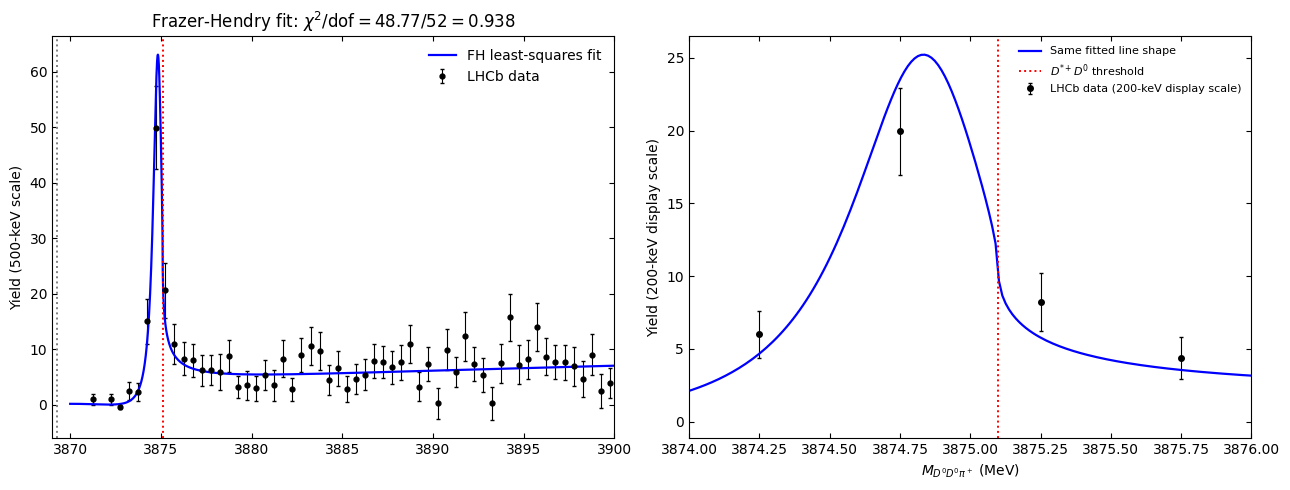

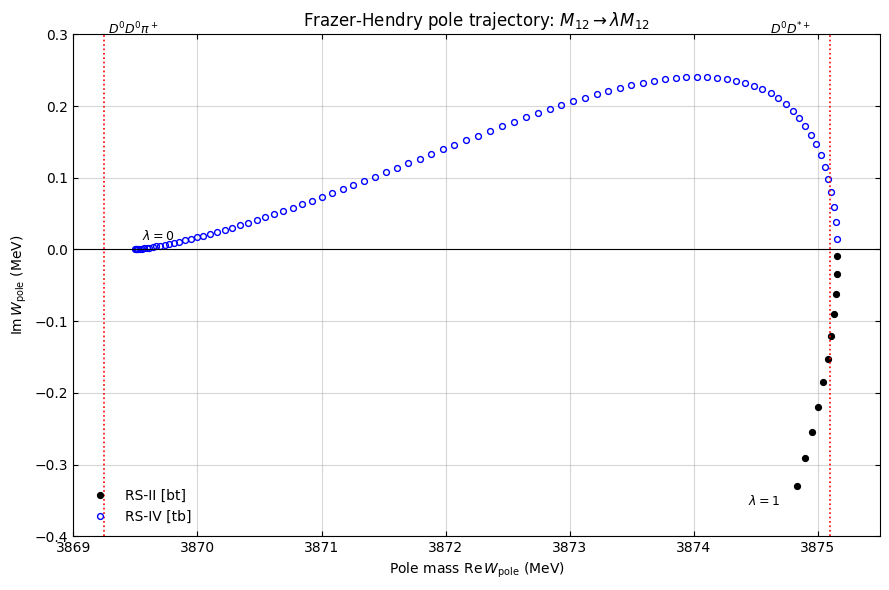

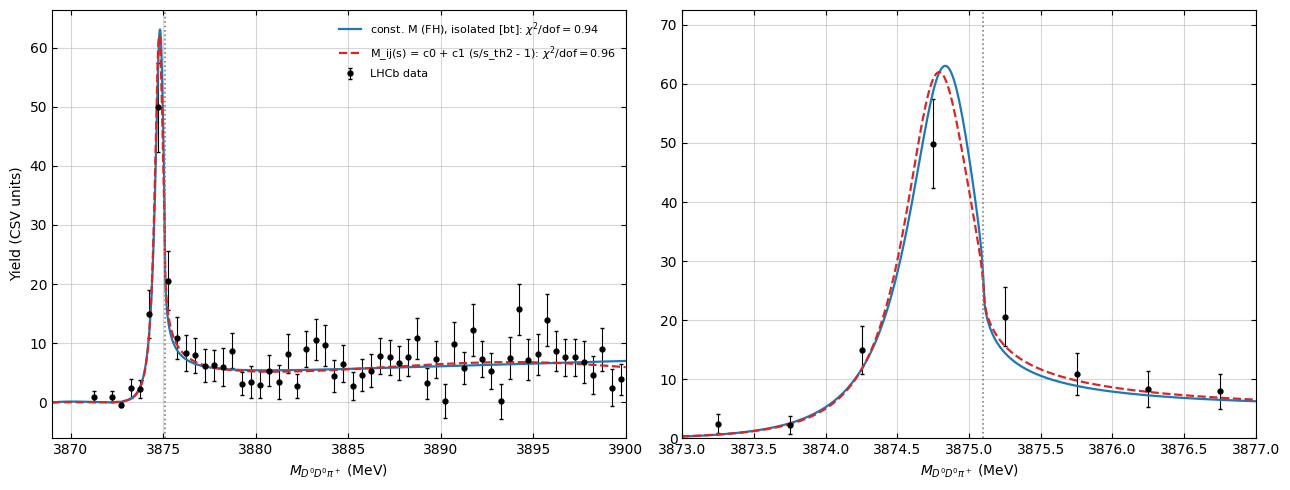

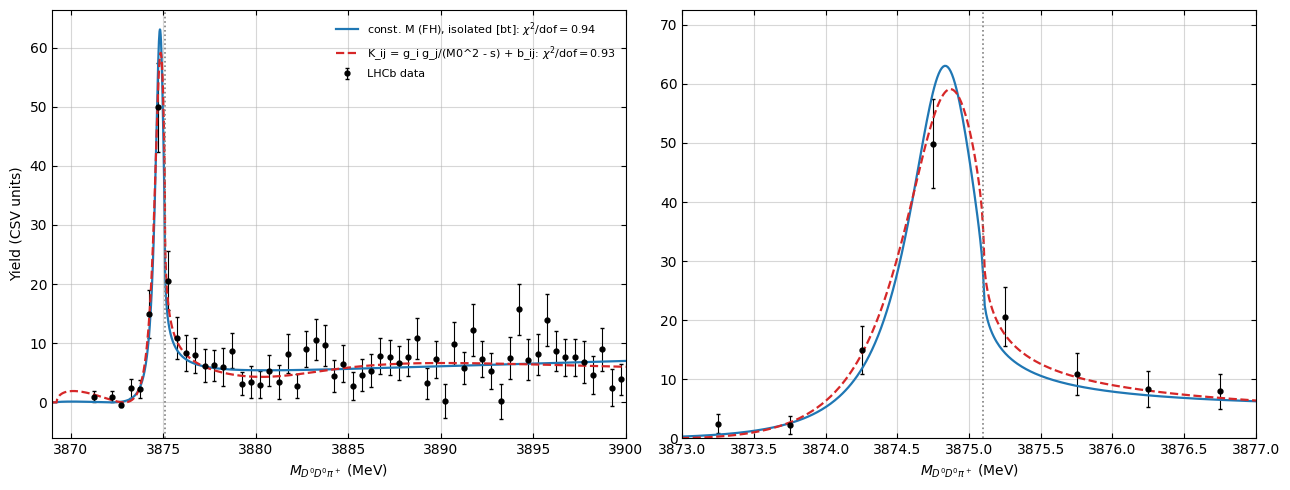

In [267]:
if __name__ == "__main__":
    warnings.filterwarnings("ignore", category=RuntimeWarning)
    main()